In [12]:
import pandas as pd

path = "../data/raw/cs-training.csv"
df = pd.read_csv(path, index_col=0)

In [13]:
print(df.shape)
print()
print(df.dtypes)
print()
print("Missing values:")
print(df.isna().sum())
print()
print("Persentase default (target):")
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

(150000, 11)

SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

Missing values:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime6

In [7]:
late_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
             "NumberOfTimes90DaysLate",
             "NumberOfTime60-89DaysPastDueNotWorse"]

mask_code = (df[late_cols] >= 96).any(axis=1)
print("Baris dengan kode 96/98:", mask_code.sum())
print("Default rate baris kode 96/98:", round(df.loc[mask_code, "SeriousDlqin2yrs"].mean(), 3))
print("Default rate baris lainnya:", round(df.loc[~mask_code, "SeriousDlqin2yrs"].mean(), 3))
print()

high_dr = df["DebtRatio"] > 10
print("DebtRatio > 10:", high_dr.sum())
print("  - di antaranya income kosong:", (high_dr & df["MonthlyIncome"].isna()).sum())
print("  - default rate:", round(df.loc[high_dr, "SeriousDlqin2yrs"].mean(), 3))
print()

print("Utilization > 10:", (df["RevolvingUtilizationOfUnsecuredLines"] > 10).sum())
print("MonthlyIncome == 0:", (df["MonthlyIncome"] == 0).sum())

Baris dengan kode 96/98: 269
Default rate baris kode 96/98: 0.546
Default rate baris lainnya: 0.066

DebtRatio > 10: 28877
  - di antaranya income kosong: 26771
  - default rate: 0.056

Utilization > 10: 241
MonthlyIncome == 0: 1634


In [8]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(
    df, test_size=0.30, stratify=df["SeriousDlqin2yrs"], random_state=42
)
val, test = train_test_split(
    temp, test_size=0.50, stratify=temp["SeriousDlqin2yrs"], random_state=42
)

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, d.shape, round(d["SeriousDlqin2yrs"].mean(), 4))

train.to_csv("../data/clean/train.csv", index=False)
val.to_csv("../data/clean/val.csv", index=False)
test.to_csv("../data/clean/test.csv", index=False)

train (105000, 11) 0.0668
val (22500, 11) 0.0668
test (22500, 11) 0.0668


In [9]:
import sys, os, joblib
sys.path.append("..")
from src.cleaning import fit_cleaner, apply_cleaner

train = pd.read_csv("../data/clean/train.csv")
val = pd.read_csv("../data/clean/val.csv")
test = pd.read_csv("../data/clean/test.csv")

params = fit_cleaner(train)
print(params)

train_c = apply_cleaner(train, params)
val_c = apply_cleaner(val, params)
test_c = apply_cleaner(test, params)

os.makedirs("../models", exist_ok=True)
joblib.dump(params, "../models/cleaning_params.joblib")
train_c.to_csv("../data/clean/train_clean.csv", index=False)
val_c.to_csv("../data/clean/val_clean.csv", index=False)
test_c.to_csv("../data/clean/test_clean.csv", index=False)

print()
print("Sisa nilai kosong (train/val/test):",
      train_c.isna().sum().sum(), val_c.isna().sum().sum(), test_c.isna().sum().sum())
print("Flag di train:", train_c[["income_missing", "late_code_flag"]].sum().to_dict())
print(train_c.describe().T[["min", "50%", "max"]])

{'age_median': np.float64(52.0), 'late_median': {'NumberOfTime30-59DaysPastDueNotWorse': np.float64(0.0), 'NumberOfTimes90DaysLate': np.float64(0.0), 'NumberOfTime60-89DaysPastDueNotWorse': np.float64(0.0)}, 'income_median': np.float64(5382.0), 'debtratio_median': np.float64(0.297070293), 'dependents_median': np.float64(0.0), 'cap_util': np.float64(1.0953084438899974), 'cap_debtratio': np.float64(655.0), 'cap_income': np.float64(25000.0)}

Sisa nilai kosong (train/val/test): 0 0 0
Flag di train: {'income_missing': 20723, 'late_code_flag': 182}
                                        min       50%        max
SeriousDlqin2yrs                      0.000     0.000      1.000
RevolvingUtilizationOfUnsecuredLines  0.000     0.154      1.095
age                                  21.000    52.000    109.000
NumberOfTime30-59DaysPastDueNotWorse  0.000     0.000     13.000
DebtRatio                             0.000     0.297    655.000
MonthlyIncome                         0.000 5,382.000 25,000

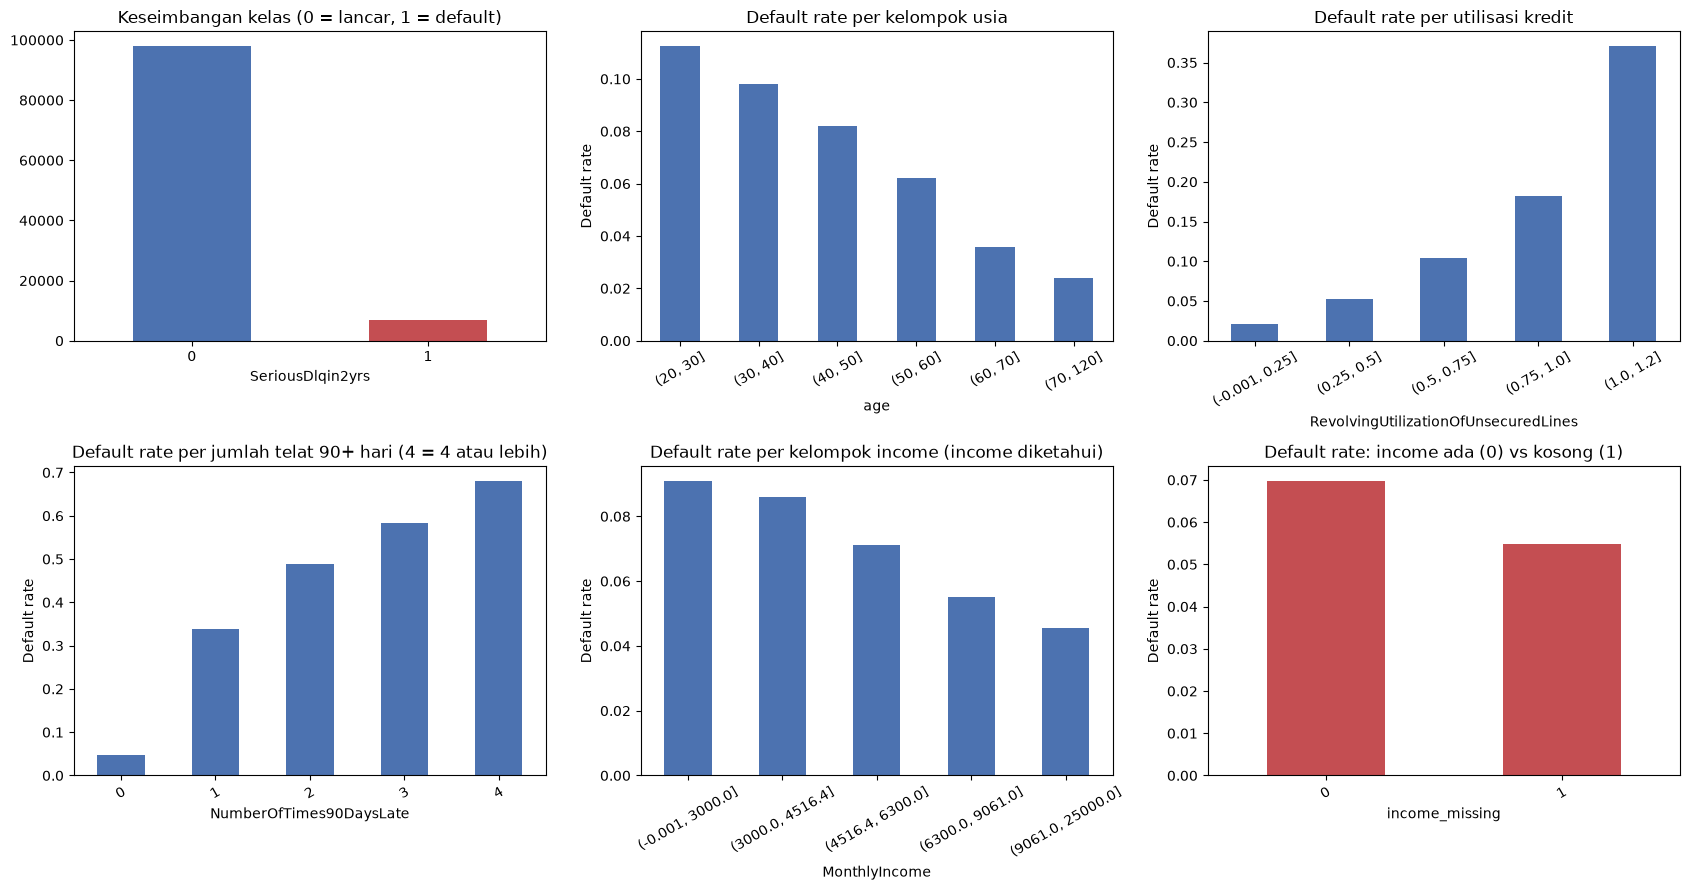

In [10]:
import matplotlib.pyplot as plt

tr = pd.read_csv("../data/clean/train_clean.csv")
target = "SeriousDlqin2yrs"

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()

# 1. Keseimbangan kelas
tr[target].value_counts().sort_index().plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Keseimbangan kelas (0 = lancar, 1 = default)")
axes[0].set_xticklabels(["0", "1"], rotation=0)

# 2. Default rate per kelompok usia
age_bin = pd.cut(tr["age"], [20, 30, 40, 50, 60, 70, 120])
tr.groupby(age_bin, observed=True)[target].mean().plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set_title("Default rate per kelompok usia")

# 3. Default rate per utilisasi kredit
util_bin = pd.cut(tr["RevolvingUtilizationOfUnsecuredLines"], [-0.001, 0.25, 0.5, 0.75, 1.0, 1.2])
tr.groupby(util_bin, observed=True)[target].mean().plot.bar(ax=axes[2], color="#4C72B0")
axes[2].set_title("Default rate per utilisasi kredit")

# 4. Default rate per jumlah telat 90+ hari
late90 = tr["NumberOfTimes90DaysLate"].clip(upper=4)
tr.groupby(late90)[target].mean().plot.bar(ax=axes[3], color="#4C72B0")
axes[3].set_title("Default rate per jumlah telat 90+ hari (4 = 4 atau lebih)")

# 5. Default rate per kelompok income (hanya yang incomenya diketahui)
known = tr[tr["income_missing"] == 0]
inc_bin = pd.qcut(known["MonthlyIncome"], 5, duplicates="drop")
known.groupby(inc_bin, observed=True)[target].mean().plot.bar(ax=axes[4], color="#4C72B0")
axes[4].set_title("Default rate per kelompok income (income diketahui)")

# 6. Income kosong vs ada
tr.groupby("income_missing")[target].mean().plot.bar(ax=axes[5], color="#C44E52")
axes[5].set_title("Default rate: income ada (0) vs kosong (1)")
axes[5].set_xticklabels(["0", "1"], rotation=0)

for ax in axes[1:]:
    ax.set_ylabel("Default rate")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../reports/eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()